# Augmentation gallery

A tour of the transforms of `acids_dataset.transforms`, by family, on the same test signal : a short melody with
drums. Each transform is applied with `_force_transform=True` (whatever its probability), and shown as a
spectrogram ; a few of them can be listened to.

Every constructor below is written with **all of its arguments**, set to their default values, so that they can be read and tweaked directly. For transforms wrapped from [audiomentations](https://iver56.github.io/audiomentations/), `sr` is forwarded as `sample_rate`, and `p` defaults to `1.0` (instead of audiomentations' `0.5`). The `min_*` / `max_*` pairs define the ranges from which parameters are randomly drawn at each call.

In [1]:
import math, tempfile, warnings
from pathlib import Path
import numpy as np
import soundfile as sf
import torch
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from acids_dataset import transforms as adt

warnings.filterwarnings("ignore")
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("jpeg")                        # spectrograms of noisy signals are much lighter in jpeg
plt.rcParams["figure.dpi"] = 72
SR = 16000
torch.manual_seed(0); np.random.seed(0)
t = torch.arange(2 * SR) / SR

def note(f0, start, duration=0.25):
    env = ((t >= start) & (t < start + duration)).float() * torch.exp(-(t - start).clamp(min=0) * 8)
    return env * sum(0.25 / k * torch.sin(2 * math.pi * f0 * k * t) for k in range(1, 8))

melody = sum(note(f, 0.25 * i) for i, f in enumerate([262, 330, 392, 523, 392, 330, 262, 196]))
hats = sum(torch.randn(len(t)) * ((t >= s) & (t < s + 0.03)).float() * 0.1 for s in np.arange(0, 2, 0.125))
x = (melody + hats)[None]

def spectrogram(ax, y, title):
    y = torch.as_tensor(np.asarray(y)).float().reshape(-1, np.asarray(y).shape[-1])[0]
    spec = torch.stft(y, 512, 256, window=torch.hann_window(512), return_complex=True).abs()
    ax.imshow(20 * torch.log10(spec + 1e-5), origin="lower", aspect="auto", cmap="magma", vmin=-70, vmax=10,
              extent=[0, len(y) / SR, 0, SR / 2000])
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])

def gallery(transforms, ncols=4, listen=()):
    items = [("original", None)] + list(transforms.items())
    nrows = math.ceil(len(items) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.2 * nrows))
    for ax in axes.flat: ax.axis("off")
    outputs = {}
    for ax, (name, tr) in zip(axes.flat, items):
        y = x if tr is None else tr(x, _force_transform=True)
        outputs[name] = y
        ax.axis("on"); spectrogram(ax, y, name)
    plt.tight_layout(); plt.show()
    for name in listen:
        print(name); display(Audio(np.asarray(outputs[name]).reshape(-1, np.asarray(outputs[name]).shape[-1])[0], rate=SR))

display(Audio(x[0].numpy(), rate=SR))

## Gain and dynamics

Failed to import loudness. Maybe it is not installed? To install the optional loudness dependency of audiomentations, do `pip install audiomentations[extras]` or simply  `pip install loudness`


ModuleNotFoundError: No module named 'loudness'

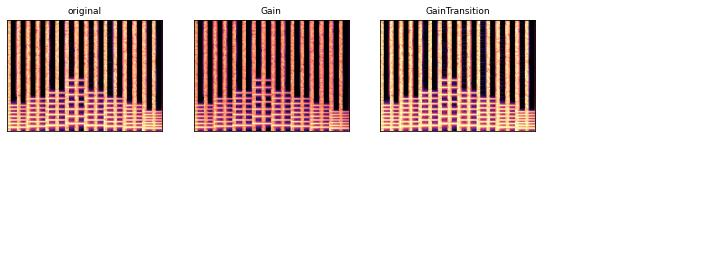

In [2]:
gallery({
    "Gain": adt.Gain(
        min_gain_db=-12.0, max_gain_db=12.0, p=1.0, sr=SR, name=None, pad_mode="zero"),
    "GainTransition": adt.GainTransition(
        min_gain_db=-24.0, max_gain_db=6.0, min_duration=0.2, max_duration=6.0, duration_unit="seconds", p=1.0,
        sr=SR, name=None, pad_mode="zero"),
    "LoudnessNormalization": adt.LoudnessNormalization(
        min_lufs=-31.0, max_lufs=-13.0, p=1.0, sr=SR, name=None, pad_mode="zero"),
    "Normalize": adt.Normalize(
        apply_to="all", p=1.0, sr=SR, name=None, pad_mode="zero"),
    "Mute": adt.Mute(
        p=0.1, noise_std=1e-05, sr=SR, name=None, rand_batchwise=True),
    "TimeMask": adt.TimeMask(
        min_band_part=0.01, max_band_part=0.2, fade_duration=0.005, mask_location="random", p=1.0, sr=SR,
        name=None, pad_mode="zero"),
    "PolarityInversion": adt.PolarityInversion(
        p=1.0, sr=SR, name=None, pad_mode="zero"),
}, listen=["GainTransition"])

## Filters and equalization

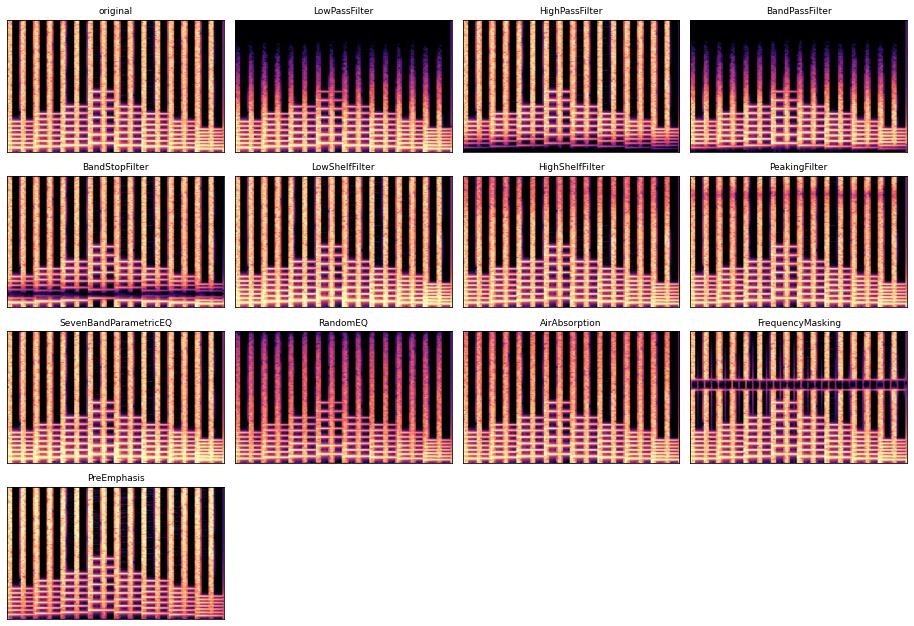

RandomEQ


In [ ]:
gallery({
    "LowPassFilter": adt.LowPassFilter(
        min_cutoff_freq=150.0, max_cutoff_freq=7500.0, min_rolloff=12, max_rolloff=24, zero_phase=False, p=1.0,
        sr=SR, name=None, pad_mode="zero"),
    "HighPassFilter": adt.HighPassFilter(
        min_cutoff_freq=20.0, max_cutoff_freq=2400.0, min_rolloff=12, max_rolloff=24, zero_phase=False, p=1.0,
        sr=SR, name=None, pad_mode="zero"),
    "BandPassFilter": adt.BandPassFilter(
        min_center_freq=200.0, max_center_freq=4000.0, min_bandwidth_fraction=0.5, max_bandwidth_fraction=1.99,
        min_rolloff=12, max_rolloff=24, zero_phase=False, p=1.0, sr=SR, name=None, pad_mode="zero"),
    "BandStopFilter": adt.BandStopFilter(
        min_center_freq=200.0, max_center_freq=4000.0, min_bandwidth_fraction=0.5, max_bandwidth_fraction=1.99,
        min_rolloff=12, max_rolloff=24, zero_phase=False, p=1.0, sr=SR, name=None, pad_mode="zero"),
    "LowShelfFilter": adt.LowShelfFilter(
        min_center_freq=50.0, max_center_freq=4000.0, min_gain_db=-18.0, max_gain_db=18.0, min_q=0.1,
        max_q=0.999, p=1.0, sr=SR, name=None, pad_mode="zero"),
    "HighShelfFilter": adt.HighShelfFilter(
        min_center_freq=300.0, max_center_freq=7500.0, min_gain_db=-18.0, max_gain_db=18.0, min_q=0.1,
        max_q=0.999, p=1.0, sr=SR, name=None, pad_mode="zero"),
    "PeakingFilter": adt.PeakingFilter(
        min_center_freq=50.0, max_center_freq=7500.0, min_gain_db=-24.0, max_gain_db=24.0, min_q=0.5, max_q=5.0,
        p=1.0, sr=SR, name=None, pad_mode="zero"),
    "SevenBandParametricEQ": adt.SevenBandParametricEQ(
        min_gain_db=-12.0, max_gain_db=12.0, p=1.0, sr=SR, name=None, pad_mode="zero"),
    "RandomEQ": adt.RandomEQ(
        p_lp=0.75, p_bp=0.5, n_bp=2, p_ls=0.5, sr=SR, name=None, p=None, rand_batchwise=True),
    "AirAbsorption": adt.AirAbsorption(
        min_temperature=10.0, max_temperature=20.0, min_humidity=30.0, max_humidity=90.0, min_distance=10.0,
        max_distance=100.0, p=1.0, sr=SR, name=None, pad_mode="zero"),
    "FrequencyMasking": adt.FrequencyMasking(
        p=0.5, n_fft=4096, max_size=512, sr=SR, name=None, rand_batchwise=True),
    "PreEmphasis": adt.PreEmphasis(
        coeff=0.97, sr=SR, name=None, p=None, rand_batchwise=True),
}, listen=["RandomEQ"])

## Noise

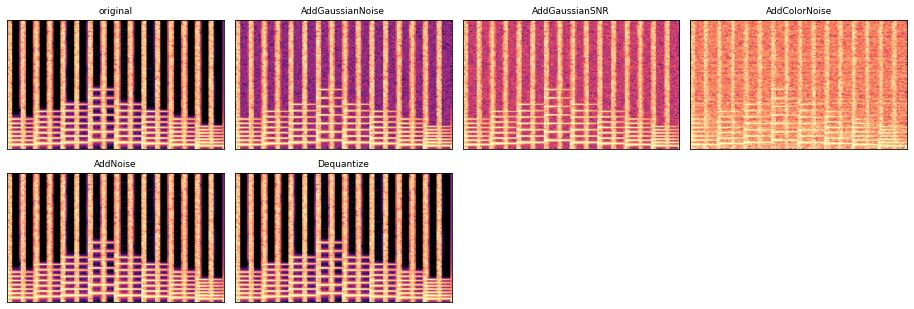

AddColorNoise


In [ ]:
gallery({
    "AddGaussianNoise": adt.AddGaussianNoise(
        min_amplitude=0.001, max_amplitude=0.015, p=1.0, sr=SR, name=None, pad_mode="zero"),
    "AddGaussianSNR": adt.AddGaussianSNR(
        min_snr_db=5.0, max_snr_db=40.0, p=1.0, sr=SR, name=None, pad_mode="zero"),
    "AddColorNoise": adt.AddColorNoise(
        min_snr_db=5.0, max_snr_db=40.0, min_f_decay=-6.0, max_f_decay=6.0, p_apply_a_weighting=0.0, n_fft=128,
        p=1.0, sr=SR, name=None, pad_mode="zero"),
    "AddNoise": adt.AddNoise(
        std=1e-2, sr=SR, name=None, p=None, rand_batchwise=True),
    "Dequantize": adt.Dequantize(
        bit_depth=16, sr=SR, name=None, p=None, rand_batchwise=True),
}, listen=["AddColorNoise"])

## Distortion and degradation

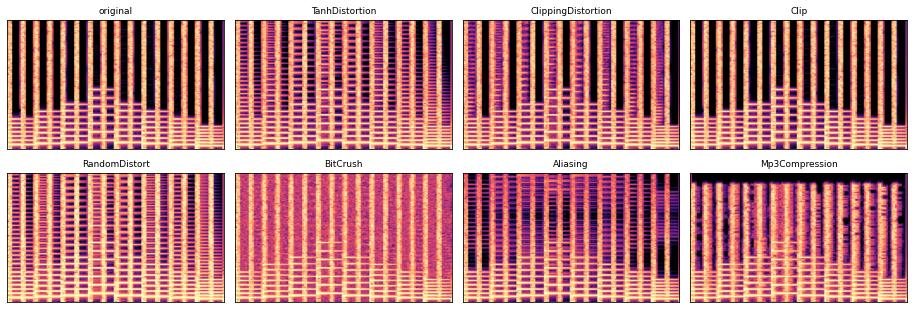

RandomDistort


Mp3Compression


In [ ]:
gallery({
    "TanhDistortion": adt.TanhDistortion(
        min_distortion=0.01, max_distortion=0.7, p=1.0, sr=SR, name=None, pad_mode="zero"),
    "ClippingDistortion": adt.ClippingDistortion(
        min_percentile_threshold=0, max_percentile_threshold=40, p=1.0, sr=SR, name=None, pad_mode="zero"),
    "Clip": adt.Clip(
        a_min=-1.0, a_max=1.0, p=1.0, sr=SR, name=None, pad_mode="zero"),
    "RandomDistort": adt.RandomDistort(
        sr=SR, max_drive=32, p_lp=0.75, p_bp=0.5, n_bp=2, p_ls=0.5, name=None, p=None, rand_batchwise=True),
    "BitCrush": adt.BitCrush(
        min_bit_depth=5, max_bit_depth=10, p=1.0, sr=SR, name=None, pad_mode="zero"),
    "Aliasing": adt.Aliasing(
        min_sample_rate=8000, max_sample_rate=30000, p=1.0, sr=SR, name=None, pad_mode="zero"),
    "Mp3Compression": adt.Mp3Compression(
        min_bitrate=8, max_bitrate=64, backend="pydub", p=1.0, sr=SR, name=None, pad_mode="zero"),
}, listen=["RandomDistort", "Mp3Compression"])

## Time and pitch

`Stretch` resamples the signal (speed and pitch change together) with polyphase filtering ; `PitchShift` and
`TimeStretch` change pitch and duration independently.

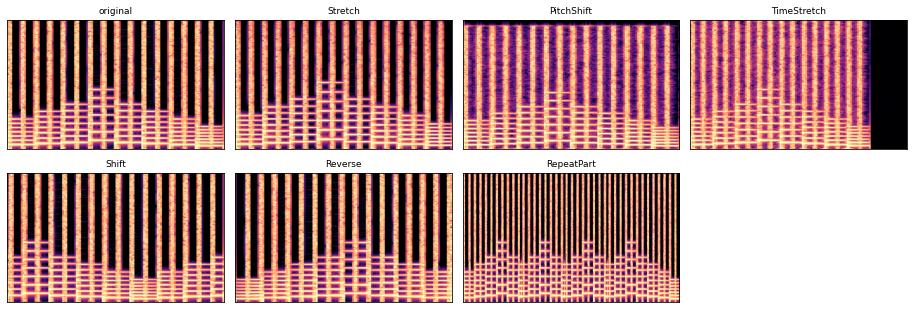

Stretch


PitchShift


In [ ]:
gallery({
    "Stretch": adt.Stretch(
        n_signal=None, pitch_range=None, max_factor=20, p=0.5, loudness_correction=True, sr=SR, name=None,
        rand_batchwise=True),
    "PitchShift": adt.PitchShift(
        min_semitones=-4.0, max_semitones=4.0, method="signalsmith_stretch", p=1.0, sr=SR, name=None,
        pad_mode="zero"),
    "TimeStretch": adt.TimeStretch(
        min_rate=0.8, max_rate=1.25, leave_length_unchanged=True, method="signalsmith_stretch", p=1.0, sr=SR,
        name=None, pad_mode="zero"),
    "Shift": adt.Shift(
        min_shift=-0.5, max_shift=0.5, shift_unit="fraction", rollover=True, fade_duration=0.005, p=1.0, sr=SR,
        name=None, pad_mode="zero"),
    "Reverse": adt.Reverse(
        p=1.0, sr=SR, name=None, pad_mode="zero"),
    "RepeatPart": adt.RepeatPart(
        min_repeats=1, max_repeats=3, min_part_duration=0.25, max_part_duration=1.2, mode="insert",
        crossfade_duration=0.005, part_transform=None, p=1.0, sr=SR, name=None, pad_mode="zero"),
}, listen=["Stretch", "PitchShift"])

## Phase and delays

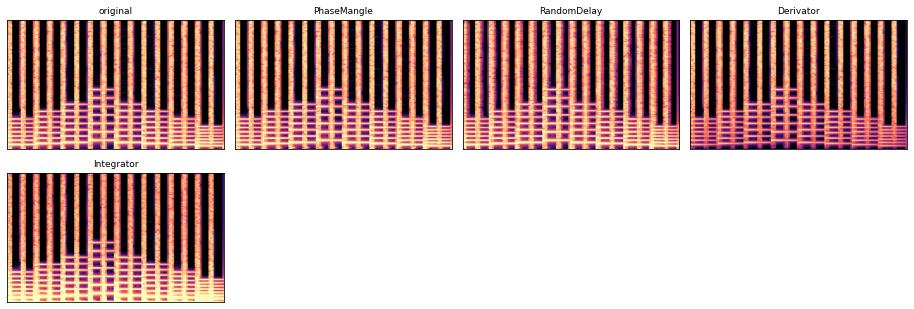

RandomDelay


In [ ]:
gallery({
    "PhaseMangle": adt.PhaseMangle(
        p=0.8, min_f=20, max_f=2000, amplitude=0.99, sr=SR, name=None, rand_batchwise=True),
    "RandomDelay": adt.RandomDelay(
        max_delay=1024, sr=SR, name=None, p=None, rand_batchwise=True),
    "Derivator": adt.Derivator(
        sr=SR, name=None, p=None, rand_batchwise=True),
    "Integrator": adt.Integrator(
        sr=SR, name=None, p=None, rand_batchwise=True),
}, listen=["RandomDelay"])

## Rooms, impulse responses and background sounds

`RoomSimulator` simulates a shoebox room (pyroomacoustics). `ApplyImpulseResponse` convolves with impulse responses
from a folder, and `AddBackgroundNoise` / `AddShortNoises` mix sounds from a folder : we generate some first.

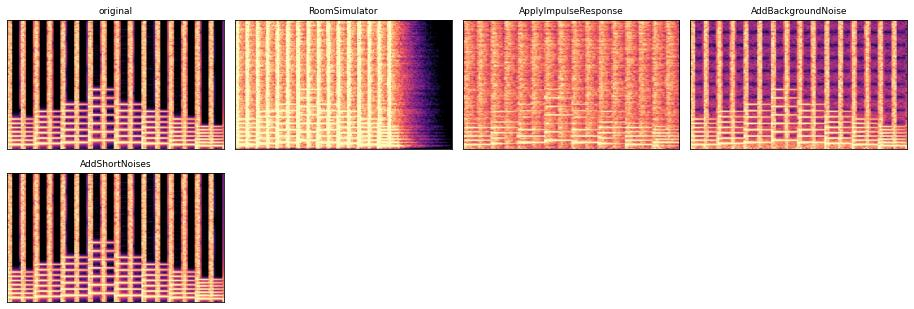

ApplyImpulseResponse


In [ ]:
folder = Path(tempfile.mkdtemp())
(folder / "irs").mkdir(); (folder / "noises").mkdir()
for i, rt60 in enumerate([0.3, 0.8, 1.5]):
    tt = np.arange(int(rt60 * SR)) / SR
    ir = np.random.randn(len(tt)) * np.exp(-6.9 * tt / rt60); ir[0] = 1.
    sf.write(folder / "irs" / f"ir_{i}.wav", 0.5 * ir / np.abs(ir).max(), SR)
for i in range(3):
    babble = np.convolve(np.random.randn(2 * SR), np.ones(20) / 20, mode="same")
    sf.write(folder / "noises" / f"noise_{i}.wav", 0.3 * babble / np.abs(babble).max(), SR)

gallery({
    "RoomSimulator": adt.RoomSimulator(
        min_size_x=3.6, max_size_x=5.6, min_size_y=3.6, max_size_y=3.9, min_size_z=2.4, max_size_z=3.0,
        min_absorption_value=0.075, max_absorption_value=0.4, min_target_rt60=0.15, max_target_rt60=0.8,
        min_source_x=0.1, max_source_x=3.5, min_source_y=0.1, max_source_y=2.7, min_source_z=1.0,
        max_source_z=2.1, min_mic_distance=0.15, max_mic_distance=0.35, min_mic_azimuth=-math.pi,
        max_mic_azimuth=math.pi, min_mic_elevation=-math.pi, max_mic_elevation=math.pi,
        calculation_mode="absorption", use_ray_tracing=True, max_order=1, leave_length_unchanged=False,
        padding=0.1, ray_tracing_options=None, p=1.0, sr=SR, name=None, pad_mode="zero"),
    "ApplyImpulseResponse": adt.ApplyImpulseResponse(
        ir_path=str(folder / "irs"), lru_cache_size=128, leave_length_unchanged=True, p=1.0, sr=SR, name=None,
        pad_mode="zero"),
    "AddBackgroundNoise": adt.AddBackgroundNoise(
        sounds_path=str(folder / "noises"), min_snr_db=3.0, max_snr_db=30.0, noise_rms="relative",
        min_absolute_rms_db=-45.0, max_absolute_rms_db=-15.0, noise_transform=None, lru_cache_size=2, p=1.0,
        sr=SR, name=None, pad_mode="zero"),
    "AddShortNoises": adt.AddShortNoises(
        sounds_path=str(folder / "noises"), min_snr_db=-6.0, max_snr_db=18.0, min_time_between_sounds=2.0,
        max_time_between_sounds=8.0, noise_rms="relative_to_whole_input", min_absolute_noise_rms_db=-50.0,
        max_absolute_noise_rms_db=-20.0, add_all_noises_with_same_level=False,
        include_silence_in_noise_rms_estimation=True, burst_probability=0.22, min_pause_factor_during_burst=0.1,
        max_pause_factor_during_burst=1.1, min_fade_in_time=0.005, max_fade_in_time=0.08,
        min_fade_out_time=0.01, max_fade_out_time=0.1, signal_gain_in_db_during_noise=None,
        signal_gain_db_during_noise=None, noise_transform=None, lru_cache_size=64, p=1.0, sr=SR, name=None,
        pad_mode="zero"),
}, listen=["ApplyImpulseResponse"])

Some transforms need optional dependencies, and are not shown here : `Compress` (torchaudio's sox effects) and
`Limiter` (`cylimiter`). `Lambda` wraps any function as a transform, and `BasicPitch` transcribes audio to MIDI.

In [ ]:
square = adt.Lambda(
    transform=lambda y, sample_rate: np.sign(y) * np.abs(y) ** 0.5, p=1.0, sr=SR, name=None, pad_mode="zero")    # called with (samples, sample_rate)
print(type(square(x)).__name__, tuple(square(x).shape))

Tensor (1, 32000)
